# Figure 3. Errors increase with time Off, and the decline in performance points to a trace of about 120 ms

**a.** Model prediction: one silence of fixed length in the delay; does the memory survive? NMDA model vs a model
where short-term facilitation replaces NMDA (STP). **b.** In the recordings, which On/Off statistic of a trial
predicts an error (logistic mixed model, `behaviour.glmm_single`)? **c, d.** The NMDA time constant that best
links time Off to the monkeys' performance (`behaviour.fit_tau`).

Runs in about 2 minutes (the tau sweep behind c, d is loaded unless `RECOMPUTE_SWEEP`).

In [1]:
import numpy as np, pandas as pd
from nmdaint import behaviour, memory, paths, ratemodel, readout
from plots import fig3, style

## Parameters

In [2]:
MODELS = {'nmda': ratemodel.params('nmda'), 'stp': ratemodel.params('stp')}
LENGTHS = np.arange(0, 1001, 25)           # a: silence (dip) lengths, ms
N_DIP, ONSET = 300, 500                    # a: trials per length; dip onset after the cue (ms)
MONKEYS = ['A', 'H', 'J']                  # b-d: e.g. ['H', 'J'] to leave out monkey A
RECOMPUTE_SWEEP, N_SWEEP = False, 30000    # c, d: rerun the tau sweep (~20 min at 30,000 trials per tau)

## a. One silence of fixed length

In [3]:
single_dip = {m: (LENGTHS, np.full(len(LENGTHS), N_DIP), memory.single_dip(p, LENGTHS, N_DIP, ONSET))
              for m, p in MODELS.items()}
for m, (L, n, held) in single_dip.items():
    print(f'{m}: memory lost from a silence of {L[np.argmax(held / n < 0.5)] if (held / n < 0.5).any() else "> " + str(L[-1])} ms')

nmda: memory lost from a silence of 375 ms
stp: memory lost from a silence of > 1000 ms


## b. On/Off statistics and errors
One row per trial, correct and error trials, all-units decoder (`scripts/recordings.py`). For each statistic,
`error ~ z(statistic) + monkey + (1 + z(statistic) || session)`; the statistic is z-scored within session.

In [4]:
trials = pd.read_csv(paths.results('recordings', 'per_trial.csv'))
trials = trials[trials.monkey.isin(MONKEYS)]
glmm, weights = behaviour.glmm_single(trials)
glmm[['predictor', 'odds_ratio_per_sd', 'or_ci_lo', 'or_ci_hi', 'p_lrt', 'p_wald']].round(5)

,predictor,odds_ratio_per_sd,or_ci_lo,or_ci_hi,p_lrt,p_wald
0,frac_off,1.35976,1.21500,1.52176,0.00001,0.00000
1,n_off,1.01057,0.94098,1.08531,0.78268,0.77271
2,off_len_ms,1.24645,1.13982,1.36306,0.00011,0.00000
3,frac_on,0.81848,0.73169,0.91555,0.00115,0.00046


## c, d. The NMDA time constant fitted to performance
P(memory held | fraction of the delay Off) is simulated for 17 values of tau_N (`memory.tau_sweep`), then
P(correct) = p0 x [P(held) + (1 - P(held)) / 8] is fitted to all trials pooled, with a bootstrap over sessions.

In [5]:
if RECOMPUTE_SWEEP:
    ses, _ = readout.load_data()
    gain = memory.reference_gain(MODELS['nmda'], ses)
    rows = []
    for tau in memory.TAUS:
        frac, held = memory.tau_sweep(MODELS['nmda'], tau, gain, N_SWEEP)
        b = behaviour.bins(frac)
        rows += [dict(tau_ms=tau, bin=j, n=(b == j).sum(), held=held[b == j].sum()) for j in range(behaviour.NB)]
    sweep = pd.DataFrame(rows)
else:
    sweep = pd.read_csv(paths.results('ratemodel', 'tau_sweep.csv'))
taus = np.sort(sweep.tau_ms.unique())
counts = lambda c: sweep.pivot(index='tau_ms', columns='bin', values=c).loc[taus].values
fine, held_curve = behaviour.held_curves(taus, counts('held'), counts('n'))
tau = behaviour.fit_tau(trials, fine, held_curve)
tau['bin_ms'] = 900 * (behaviour.EDGES[:-1] + np.minimum(behaviour.EDGES[1:], 1)) / 2
tau['p_correct_model'] = tau['p0'] * (tau['held'] + behaviour.G * (1 - tau['held']))
print(f"tau_N {tau['tau']:.0f} ms (bootstrap 95% interval {np.percentile(tau['boot'], 2.5):.0f}-"
      f"{np.percentile(tau['boot'], 97.5):.0f} ms), p0 {tau['p0']:.3f}; {int(tau['n'].sum())} trials")

tau_N 123 ms (bootstrap 95% interval 101-190 ms), p0 0.887; 15468 trials


## Figure

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


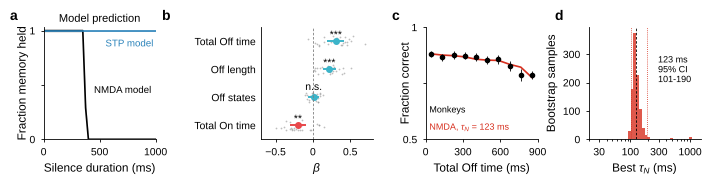

In [6]:
fig = fig3.draw(single_dip, glmm, weights, tau)
style.save(fig, '../figures/fig3.png', dpi=fig3.DPI)